## Data Exploration

This notebook explores the cleaned dataset built in `Build_Final_Dataset.ipynb` (184,664 moisturizer reviews with skin type and ingredient data).

**1. Data Exploration**
- Basic stats: dataset size, products, brands, date range, and price
- Reviews per year
- Missing values remaining after cleaning
- Review text length, overall and by star rating
- Sample reviews
- Skin type mix, overall and within products

## Setup

In [1]:
%pip install -q pandas matplotlib


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Imports and Data Load
import sys
sys.path.append("..")   # lets the notebook find the src folder one level up

import pandas as pd
import matplotlib.pyplot as plt
from src.utils import load_data, share_table, plot_bar

df = load_data()
print(f"Loaded {len(df):,} reviews")

Loaded 184,664 reviews


## 1. Data Exploration
### Basic Statistics

In [3]:
# Helper function to summarize the dataset
def summarize_dataset(df):
    """Print basic size, coverage, and price stats."""
    print(f"Reviews: {len(df):,}")
    print(f"Products: {df['product_id'].nunique()} | Brands: {df['brand_name'].nunique()}")
    print(f"Date range: {df['submission_time'].min().date()} to {df['submission_time'].max().date()}")
    prices = df.drop_duplicates("product_id")["price_usd"]
    print(f"Product price: median ${prices.median():.0f}, range ${prices.min():.0f}-${prices.max():.0f}")

In [4]:
summarize_dataset(df)

Reviews: 184,664
Products: 379 | Brands: 90
Date range: 2008-08-29 to 2023-03-21
Product price: median $59, range $8-$400


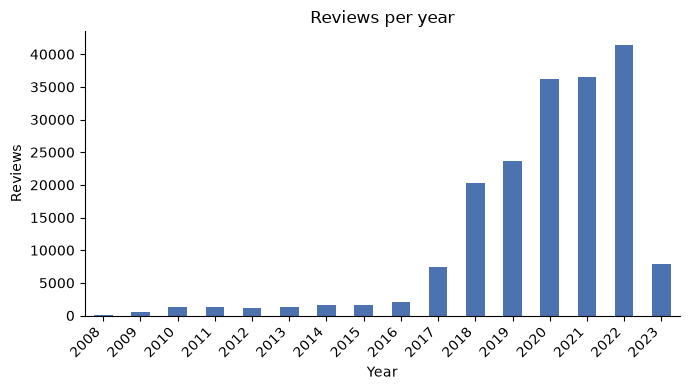

In [5]:
# Plot reviews per year
# Data was scraped in March 2023
plot_bar(df["submission_time"].dt.year.value_counts().sort_index(),
         "Reviews per year", "Year", "Reviews", rot=45)

In [6]:
# Missing values in the cleaned data
print(df.isna().sum())

author_id                0
rating                   0
submission_time          0
review_text              0
review_title         53987
skin_type                0
product_id               0
review_id                0
product_name             0
brand_name               0
price_usd                0
tertiary_category        0
ingredients              0
highlights           25061
dtype: int64


In [7]:
# Calculate the percentage of reviews between 2018 and 2022
years = df["submission_time"].dt.year
print(f"{years.between(2018, 2022).mean():.1%}")

85.7%


**Observations**
- The cleaned dataset has 184,664 reviews of 379 moisturizers from 90 brands. Product prices range from $8 to $400 (median $59), so the data covers drugstore-priced and luxury moisturizers alike.
- Reviews run from August 2008 to March 2023, but most are recent. Volume rose sharply from 2017 onward, and 2018–2022 account for 85.7% of all reviews, while no year before 2017 has more than about 2,100. The low 2023 count (7,929) reflects when the data was scraped (March 2023), not a drop in reviews, since it covers less than three months. For the Phase 3 time check, comparing earlier and later years within 2018–2022 is more reliable than going back further, where yearly counts are too small.
- `Build_Final_Dataset.ipynb` removed about 10,300 reviews that Sephora displays on both the mini and full-size versions of a product, which would otherwise be counted twice, plus reviews missing review text, skin type, ingredients, or subcategory.
- Only two columns still have gaps. Review titles are missing for 53,987 reviews (29.2%), which is acceptable because the analysis relies on review text and uses titles only when present. Highlights (Sephora's product tags) are missing for 25,061 reviews (13.6%); they will only serve as a secondary check on ingredient flags, and a blank means no tags were listed, not that a product lacks a feature.

----

### Review Text Length

count    184664.0
mean         61.4
std          42.5
min           1.0
25%          34.0
50%          51.0
75%          77.0
max         982.0
Name: review_words, dtype: float64


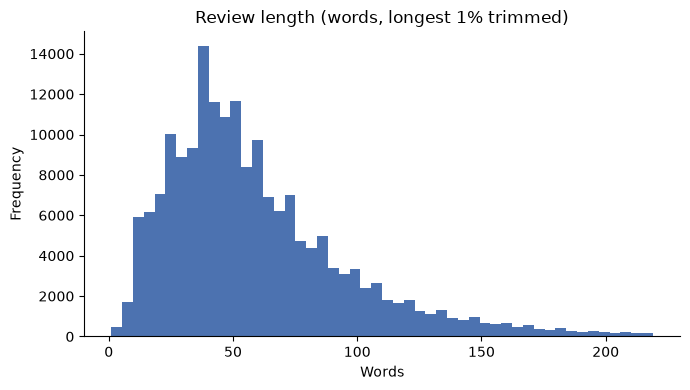

In [8]:
# A simple way to get a sense of the length of the reviews. The longest 1% are trimmed for readability.
df["review_words"] = df["review_text"].str.split().str.len()
print(df["review_words"].describe().round(1))

clip = df["review_words"].quantile(0.99)   # trim the longest 1% for readability
ax = df.loc[df["review_words"] <= clip, "review_words"].plot(
    kind="hist", bins=50, color="#4C72B0", figsize=(7, 4))
ax.set_title("Review length (words, longest 1% trimmed)")
ax.set_xlabel("Words")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [9]:
# This code snippet shows the median number of words in reviews by star rating, and the percentage of reviews that have no title.
print("Median words by star rating:")
print(df.groupby("rating")["review_words"].median())
print(f"\nReviews with no title: {df['review_title'].isna().mean():.1%}")

Median words by star rating:
rating
1    46.0
2    53.0
3    57.0
4    55.0
5    49.0
Name: review_words, dtype: float64

Reviews with no title: 29.2%


In [11]:
# Pull one review per star rating to get a sense of the text
pd.set_option("display.max_colwidth", 300)
(df.groupby("rating")
   .sample(1, random_state=42)
   [["rating", "skin_type", "product_name", "review_text"]])

,rating,skin_type,product_name,review_text
29925,1,combination,Crème de la Mer Moisturizer,"not sure what the fuss is about. every time i took some out it felt like i was taking out some cream from a particular blue tin, if you know what i mean. didn’t see any difference. overpriced. blah."
123068,2,combination,The True Cream Aqua Bomb,After seeing great reviews about this product I was pretty excited to try it out since I was in need of a new moisturizer. After using it a few times I started noticing bumps on my forehead and around my cheeks and chin. I haven’t broken out like that in such a long time. It’s hydrating and feel...
35444,3,combination,Dreamskin Skin Perfector,"I have combination skin, and used this product for over two months. Didn’t really see any difference, and only made my skin drier during peak winter and did not work well with my foundation. I don’t really think it helped correct my skin in any way either."
109532,4,combination,Greek Yoghurt Nourishing Probiotic Gel-Cream,"Great product. Unsure if it really helped my skin yet, but looking forward to using more."
101834,5,combination,Santorini Grape Poreless Skin Cream,"Honestly, I really liked this Korres Santorini Grape Poreless Skin Cream. It went on smooth and felt lightweight on my skin. It wore well under makeup and instantly hydrated my winter skin. I love that it has hyaluronic acid in it and is antioxidant rich. I would definitely recommend and would..."


**Observations**

- Reviews are fairly short. The median review is 51 words, and half fall between 34 and 77 words. The distribution has a long right tail (mean 61, max 982 words), so a small share of reviewers write in much more detail. At this length, most reviews describe one or two specific experiences, which is enough context for Claude to identify complaints in Phase 3.
- Median length peaks at 2–4 stars (53–57 words) and is shortest at 1 star (46) and 5 stars (49). Reviewers who are fully satisfied or fully dissatisfied tend to state it briefly, while mixed reviewers explain what worked and what didn't. This supports two Phase 3 design choices: labeling reviews of every rating rather than only low-rated ones, since many complaints sit inside 3- and 4-star reviews, and allowing more than one complaint per review.
- 29.2% of reviews have no title, so the review text is the primary input, with the title included only when present.
- At about 61 words per review, labeling the planned 8,000-review sample would use roughly 650,000 input tokens before adding the prompt instructions, which keeps the Batch API cost to a few dollars.

---

### Skin Type Mix

              count   pct
skin_type                
combination  100613  54.5
dry           38925  21.1
normal        24409  13.2
oily          20717  11.2


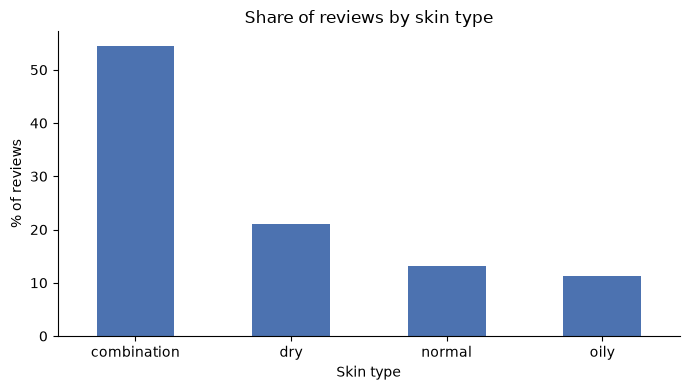

In [12]:
# Looking at the distribution of reviews by skin type
skin = share_table(df, "skin_type")
print(skin)
plot_bar(skin["pct"], "Share of reviews by skin type", "Skin type", "% of reviews")

In [13]:
# Products with 1,000+ reviews: share of each skin type within the product
big = df.groupby("product_name").filter(lambda g: len(g) >= 1000)
mix = (pd.crosstab(big["product_name"], big["skin_type"], normalize="index") * 100).round(1)

print("Products that attract the most oily-skin reviewers:")
display(mix.sort_values("oily", ascending=False).head(5))

print("Products that attract the most dry-skin reviewers:")
display(mix.sort_values("dry", ascending=False).head(5))

print("Products that attract the most normal-skin reviewers:")
display(mix.sort_values("normal", ascending=False).head(5))

print("Products that attract the most combination-skin reviewers:")
display(mix.sort_values("combination", ascending=False).head(5))

Products that attract the most oily-skin reviewers:


skin_type,combination,dry,normal,oily
product_name,,,,
Dramatically Different Moisturizing Gel,60.8,4.4,6.6,28.2
Original Skin Matte Moisturizer with Willowherb,54.1,10.6,11.6,23.7
Hello FAB Coconut Water Cream,54.5,13.4,11.6,20.4
Clear Improvement Pore Clearing Moisturizer with Salicylic Acid,60.7,10.3,9.0,20.0
Daily Greens Oil-Free Gel Moisturizer with Moringa and Papaya,61.1,9.1,9.7,20.0


Products that attract the most dry-skin reviewers:


skin_type,combination,dry,normal,oily
product_name,,,,
Cicapair Tiger Grass Cream,48.2,37.8,9.0,5.0
The Dewy Skin Cream Plumping & Hydrating Moisturizer,46.3,34.5,13.4,5.8
Ultra Repair Cream Intense Hydration,49.3,33.3,10.6,6.8
Dramatically Different Moisturizing Lotion+,50.8,30.2,12.6,6.4
Barrier+ Triple Lipid-Peptide Face Cream,51.5,30.1,11.5,7.0


Products that attract the most normal-skin reviewers:


skin_type,combination,dry,normal,oily
product_name,,,,
Dreamskin Skin Perfector,55.9,21.2,18.2,4.7
Confidence in a Cream Anti-Aging Hydrating Moisturizer,54.6,19.3,16.7,9.4
Black Tea Anti-Aging Moisturizer with Retinol-Alternative BT Matrix,53.3,21.5,16.4,8.8
Revitalizing Supreme+ Youth Power Creme Moisturizer,57.7,16.9,16.4,9.0
Cooling Water,49.4,22.7,15.9,12.0


Products that attract the most combination-skin reviewers:


skin_type,combination,dry,normal,oily
product_name,,,,
Cold Plunge Pore Remedy Moisturizer with BHA/LHA,66.2,9.5,9.5,14.8
Daily Greens Oil-Free Gel Moisturizer with Moringa and Papaya,61.1,9.1,9.7,20.0
Dramatically Different Moisturizing Gel,60.8,4.4,6.6,28.2
Clear Improvement Pore Clearing Moisturizer with Salicylic Acid,60.7,10.3,9.0,20.0
Smart Clinical Repair Wrinkle Correcting Cream,60.3,19.4,14.7,5.7


**Observations**

- Combination skin accounts for 54.5% of reviews, nearly five times the share of oily skin (11.2%), with dry at 21.1% and normal at 13.2%. Raw complaint counts would therefore mostly reflect combination-skin reviewers. Phase 3 will compare complaint **rates** within each skin type (the share of a skin type's reviews that mention a complaint) rather than raw counts.
- Skin type mix varies widely by product. Clinique's Dramatically Different Moisturizing Gel draws 28.2% of its reviews from oily skin (2.5 times the overall share) and only 4.4% from dry skin. Clinique's Dramatically Different Moisturizing Lotion+, from the same brand and product line, shows the opposite pattern: 30.2% dry and 6.4% oily. More broadly, products that attract oily skin are marketed as gels, oil-free, matte, or pore-clearing, while those that attract dry skin are rich repair and barrier creams (e.g., Cicapair Tiger Grass Cream at 37.8% dry, versus 21.1% overall).
- This sorting is strongest for oily and dry skin. Normal-skin reviewers never exceed 18.2% of a product's reviews (versus 13.2% overall), and combination-skin reviewers top out at 66.2% (versus 54.5% overall). These shoppers appear to choose products less by skin type, so the sharpest product-by-skin-type differences in Phase 3 are most likely to appear between oily and dry skin.
- Because shoppers already sort themselves, comparing complaint rates across different products would mix up product differences with differences in who buys them. Comparing skin types **within the same product** avoids this, which is why Phase 3 is built around product-by-skin-type comparisons. It also means some product–skin type groups are small (e.g., few dry-skin reviews of oil-free gels), which is why products are required to have at least 30 reviews in every skin type, and the Phase 3 sample takes an equal number of reviews per product and skin type.
- **Dataset Note:** Sephora displays the same reviews on mini and full-size versions of a product (about 10,300 duplicated reviews, or about 5%). These were removed in `Build_Final_Dataset.ipynb`, since counting them twice would inflate both review counts and complaint rates.

---